# Mini Project 4

## Agaba Steven. 
### Registration Number: S26M19/002. 
### Access Number: B38624

# Rainfall Pattern and Crop Suitability Analyser

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import find_peaks
from scipy.spatial.distance import cosine
from scipy.stats import pearsonr

from src.region import Region
from src.croprules import CropRule

In [2]:
months = [
    "Jan",
    "Feb",
    "Mar",
    "Apr",
    "May",
    "Jun",
    "Jul",
    "Aug",
    "Sep",
    "Oct",
    "Nov",
    "Dec"
]

kampala = [
    120,140,180,200,220,
    180,90,70,60,100,
    110,130
]

gulu = [
    8,25,75,160,190,
    145,170,215,175,
    150,60,15
]

mbarara = [
    70,85,120,140,90,
    25,20,55,100,
    125,120,90
]

In [3]:
regions = [
    Region(
        "Kampala",
        kampala
    ),
    Region(
        "Gulu",
        gulu
    ),
    Region(
        "Mbarara",
        mbarara
    )
]

In [4]:
stats = []

for region in regions:

    stats.append({
        "Region":
        region.name,

        "Annual Total":
        region.annual_total(),

        "Mean":
        region.mean(),

        "Wettest Month":
        months[
            region.wettest_month()
        ],

        "Driest Month":
        months[
            region.driest_month()
        ],

        "CV":
        region.coefficient_of_variation()
    })

pd.DataFrame(stats)


,Region,Annual Total,Mean,Wettest Month,Driest Month,CV
0,Kampala,1600,133.333333,May,Sep,0.371652
1,Gulu,1388,115.666667,Aug,Jan,0.614222
2,Mbarara,1040,86.666667,Apr,Jul,0.424822


In [5]:
rules = CropRule()

In [6]:
all_results = []

for region in regions:

    for month, rain in zip(
        months,
        region.rainfall
    ):

        all_results.append({
            "Region":
            region.name,

            "Month":
            month,

            "Rainfall":
            rain,

            "Suitability":
            ", ".join(
                rules.classify(
                    rain
                )
            )
        })

crop_df = pd.DataFrame(
    all_results
)

crop_df.head()

,Region,Month,Rainfall,Suitability
0,Kampala,Jan,120,"Maize, Beans, Coffee"
1,Kampala,Feb,140,"Maize, Beans, Coffee"
2,Kampala,Mar,180,"Maize, Coffee"
3,Kampala,Apr,200,"Maize, Coffee"
4,Kampala,May,220,Coffee


In [7]:
def cosine_similarity(
    a,
    b
):

    return np.dot(a, b) / (
        np.linalg.norm(a)
        *
        np.linalg.norm(b)
    )

In [8]:
print(
    cosine_similarity(
        kampala,
        gulu
    )
)

print(
    1 -
    cosine(
        kampala,
        gulu
    )
)

0.7866089874660105
0.7866089874660105


In [9]:
region_arrays = {
    "Kampala":
    np.array(kampala),

    "Gulu":
    np.array(gulu),

    "Mbarara":
    np.array(mbarara)
}

In [10]:
names = list(
    region_arrays.keys()
)

cos_matrix = pd.DataFrame(
    index=names,
    columns=names
)

for a in names:

    for b in names:

        cos_matrix.loc[a, b] = (
            cosine_similarity(
                region_arrays[a],
                region_arrays[b]
            )
        )

cos_matrix

,Kampala,Gulu,Mbarara
Kampala,1.0,0.786609,0.89125
Gulu,0.786609,1.0,0.748678
Mbarara,0.89125,0.748678,1.0


In [11]:
corr_matrix = pd.DataFrame(
    index=names,
    columns=names
)

for a in names:

    for b in names:

        corr_matrix.loc[a,b] = (
            pearsonr(
                region_arrays[a],
                region_arrays[b]
            )[0]
        )

corr_matrix

,Kampala,Gulu,Mbarara
Kampala,1.0,-0.066436,0.209347
Gulu,-0.066436,1.0,-0.173895
Mbarara,0.209347,-0.173895,1.0


In [12]:
distance_matrix = pd.DataFrame(
    index=names,
    columns=names
)

for a in names:

    for b in names:

        distance_matrix.loc[a, b] = (
            np.linalg.norm(
                region_arrays[a]
                -
                region_arrays[b]
            )
        )

distance_matrix

,Kampala,Gulu,Mbarara
Kampala,0.0,315.26814,250.399681
Gulu,315.26814,0.0,312.800256
Mbarara,250.399681,312.800256,0.0


## Why Cosine Similarity Can Be Misleading

Cosine similarity measures similarity of shape rather than magnitude. Two regions can have very similar seasonal rainfall patterns but very different rainfall totals. Consequently, cosine similarity may classify them as highly similar even when one region is significantly wetter than the other.

In [13]:
for region in regions:

    peaks, _ = find_peaks(
        region.rainfall
    )

    print(
        region.name
    )

    print(
        "Peaks:",
        [months[i]
        for i in peaks]
    )

    if len(peaks) >= 2:

        print(
            "Bimodal"
        )

    else:

        print(
            "Unimodal"
        )

    print()

Kampala
Peaks: ['May']
Unimodal

Gulu
Peaks: ['May', 'Aug']
Bimodal

Mbarara
Peaks: ['Apr', 'Oct']
Bimodal



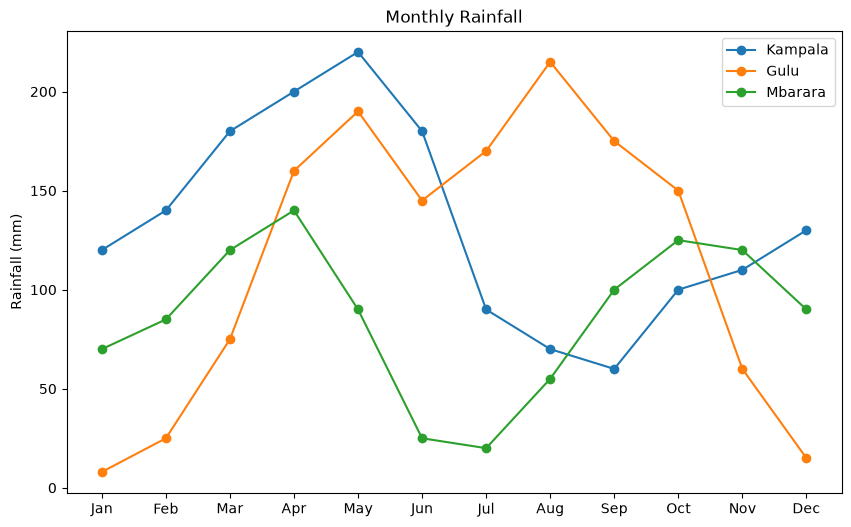

In [14]:
plt.figure(
    figsize=(10,6)
)

plt.plot(
    months,
    kampala,
    marker="o",
    label="Kampala"
)

plt.plot(
    months,
    gulu,
    marker="o",
    label="Gulu"
)

plt.plot(
    months,
    mbarara,
    marker="o",
    label="Mbarara"
)

plt.legend()

plt.title(
    "Monthly Rainfall"
)

plt.ylabel(
    "Rainfall (mm)"
)

plt.show()

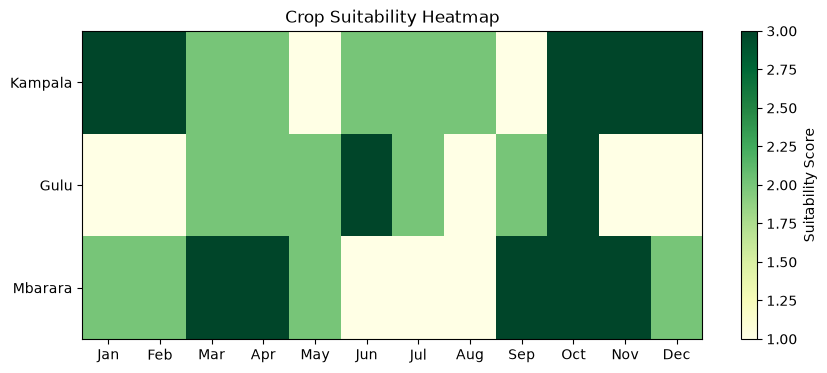

In [15]:
heatmap_data = []

for region in regions:

    values = []

    for rain in region.rainfall:

        values.append(
            len(
                rules.classify(
                    rain
                )
            )
        )

    heatmap_data.append(
        values
    )

heatmap = np.array(
    heatmap_data
)

plt.figure(
    figsize=(10,4)
)

plt.imshow(
    heatmap,
    cmap="YlGn",
    aspect="auto"
)

plt.colorbar(
    label="Suitability Score"
)

plt.yticks(
    [0,1,2],
    [
        "Kampala",
        "Gulu",
        "Mbarara"
    ]
)

plt.xticks(
    np.arange(12),
    months
)

plt.title(
    "Crop Suitability Heatmap"
)

plt.show()


# Farmer Advisory Note: Mbarara

The rainfall pattern in Mbarara indicates that the months of March, April, September, October, and November receive rainfall levels that are generally suitable for most rain-fed crops. Maize and beans are particularly suitable during these periods because rainfall amounts fall within recommended growing ranges. Farmers should prepare land before the onset of these rainy months to take advantage of available moisture. During June and July, rainfall is considerably lower and may expose crops to moisture stress if supplementary irrigation is unavailable. Coffee production can also benefit from wetter months, especially where soil moisture conservation practices are adopted. Farmers are advised to align planting schedules with the main rainy seasons and use drought-tolerant varieties where possible.


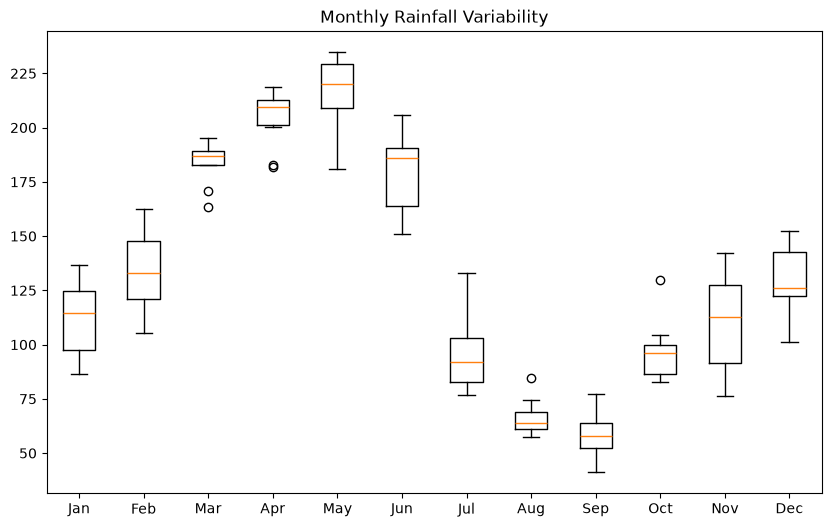

In [16]:
rng = np.random.default_rng(42)

years = []

for _ in range(10):

    years.append(
        np.array(kampala)
        +
        rng.normal(
            0,
            20,
            12
        )
    )

plt.figure(
    figsize=(10,6)
)

plt.boxplot(
    np.array(years)
)

plt.xticks(
    np.arange(
        1,
        13
    ),
    months
)

plt.title(
    "Monthly Rainfall Variability"
)

plt.show()

# Findings and Limitations

The analysis revealed noticeable differences in rainfall distribution across Kampala, Gulu, and Mbarara. Kampala recorded the highest annual rainfall totals, while Gulu exhibited stronger seasonal peaks. Peak detection identified regions with either unimodal or bimodal rainfall patterns, consistent with known climatic differences across Uganda.

The crop suitability assessment showed that maize, beans, and coffee can be supported during several months of the year, although drought-risk periods were identified, particularly in months with very low rainfall. Similarity analysis demonstrated that regions may appear highly similar using cosine similarity even when their absolute rainfall totals differ greatly. Pearson correlation and Euclidean distance provided complementary views of regional differences.

A limitation of the study is that the rainfall dataset is illustrative rather than based on observed meteorological records. In addition, crop suitability was determined solely from rainfall thresholds and did not account for soil properties, temperature, pests, elevation, or management practices. Therefore, the recommendations should be interpreted as educational planning guidance rather than definitive agronomic advice.